In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s5e5/sample_submission.csv
/kaggle/input/competitions/playground-series-s5e5/train.csv
/kaggle/input/competitions/playground-series-s5e5/test.csv


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew 

In [3]:
df = pd.read_csv('/kaggle/input/competitions/playground-series-s5e5/train.csv')
print(df.head())
df.shape

   id     Sex  Age  Height  Weight  Duration  Heart_Rate  Body_Temp  Calories
0   0    male   36   189.0    82.0      26.0       101.0       41.0     150.0
1   1  female   64   163.0    60.0       8.0        85.0       39.7      34.0
2   2  female   51   161.0    64.0       7.0        84.0       39.8      29.0
3   3    male   20   192.0    90.0      25.0       105.0       40.7     140.0
4   4  female   38   166.0    61.0      25.0       102.0       40.6     146.0


(750000, 9)

In [4]:
df['Calories'].describe()

count    750000.000000
mean         88.282781
std          62.395349
min           1.000000
25%          34.000000
50%          77.000000
75%         136.000000
max         314.000000
Name: Calories, dtype: float64

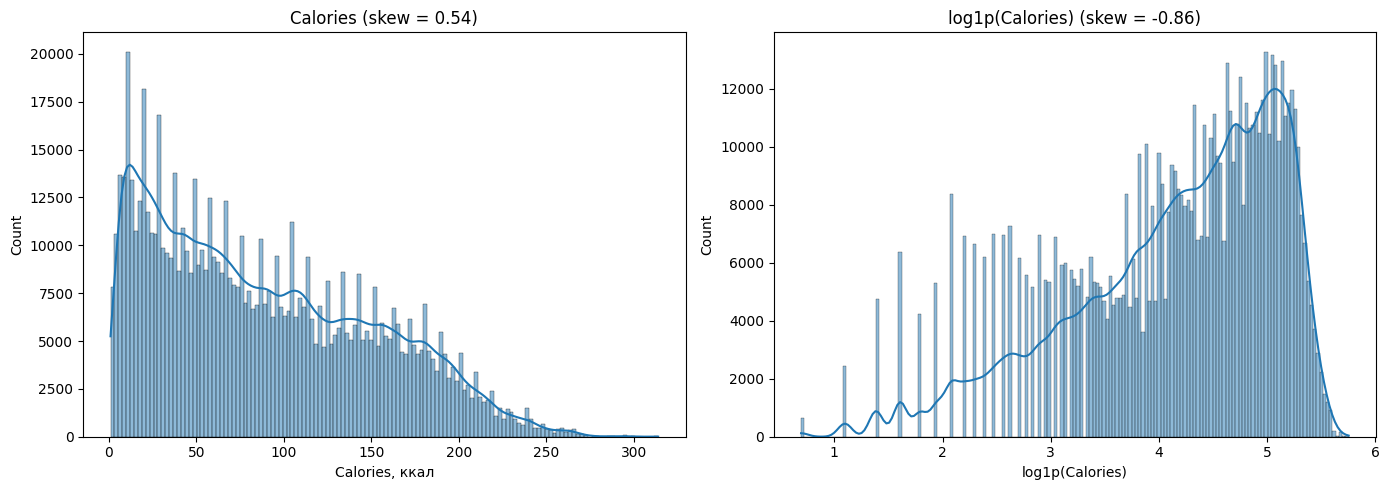

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Calories'], kde=True, ax=axes[0])
axes[0].set_title(f'Calories (skew = {df["Calories"].skew():.2f})')
axes[0].set_xlabel('Calories, ккал')

sns.histplot(np.log1p(df['Calories']), kde=True, ax=axes[1])
axes[1].set_title(f'log1p(Calories) (skew = {np.log1p(df["Calories"]).skew():.2f})')
axes[1].set_xlabel('log1p(Calories)')

plt.tight_layout()
os.makedirs('images', exist_ok=True)
plt.savefig('images/target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# Асимметрия таргета (skew) до и после log1p:
# 0 = симметрично,  > 0= хвост вправо, < 0 = хвост влево.
# log1p здесь нужен прежде всего из-за метрики RMSLE
skew_before = skew(df['Calories'])
skew_after = skew(np.log1p(df['Calories']))

print(f'Skewness до log-трансформации: {skew_before:.3f}')
print(f'Skewness после log-трансформации: {skew_after:.3f}')

Skewness до log-трансформации: 0.539
Skewness после log-трансформации: -0.857


In [7]:
# Проверка наличия пропусков
missing_count = df.isna().sum()
missing_count

id            0
Sex           0
Age           0
Height        0
Weight        0
Duration      0
Heart_Rate    0
Body_Temp     0
Calories      0
dtype: int64

In [8]:
# Логорифмируем target
y = np.log1p(df['Calories'])
print(y)
# Удаляем target и незначимый признак id
X = df.drop(columns=['id', 'Calories'])
print(X)
print(df)

0         5.017280
1         3.555348
2         3.401197
3         4.948760
4         4.990433
            ...   
749995    5.442418
749996    4.574711
749997    5.402677
749998    4.700480
749999    4.644391
Name: Calories, Length: 750000, dtype: float64
           Sex  Age  Height  Weight  Duration  Heart_Rate  Body_Temp
0         male   36   189.0    82.0      26.0       101.0       41.0
1       female   64   163.0    60.0       8.0        85.0       39.7
2       female   51   161.0    64.0       7.0        84.0       39.8
3         male   20   192.0    90.0      25.0       105.0       40.7
4       female   38   166.0    61.0      25.0       102.0       40.6
...        ...  ...     ...     ...       ...         ...        ...
749995    male   28   193.0    97.0      30.0       114.0       40.9
749996  female   64   165.0    63.0      18.0        92.0       40.5
749997    male   60   162.0    67.0      29.0       113.0       40.9
749998    male   45   182.0    91.0      17.0       10

In [9]:
# Sex -> одна колонка Sex_male (0/1). drop_first убирает лишний столбец:
# Sex_female = 1 - Sex_male, второй столбец не несёт новой информации
X = pd.get_dummies(X, columns=['Sex'], drop_first=True, dtype=int)

def add_features(DF):
    df = DF.copy()
    df['intensity'] = df['Heart_Rate'] / (220 - df['Age'])
    df['scope_Of_Work'] = df['Duration'] * df['Heart_Rate']
    df['Weight_X_Duration'] = df['Weight'] * df['Duration']
    return df

In [10]:
# Разбиение выборки на train и val 
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, random_state=42)
print(X_train.shape, X_val.shape, y_train.shape, y_val.shape)

(675000, 7) (75000, 7) (675000,) (75000,)


In [11]:
# Dummy модель
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error

# 1. создать модель
model = DummyRegressor(strategy='mean')

# 2. обучить на обучающей части
model.fit(X_train, y_train)

# 3. предсказать для проверочной части
pred = model.predict(X_val)

print(root_mean_squared_error(y_val, pred))
a = y_val.std()
print(a)

0.9644611568172016
0.9644560932208902


In [12]:
# Линейная модель
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

pred = model.predict(X_val)

root_mean_squared_error(y_val, pred)

0.17987934782425513

In [13]:
# Коэффиценты модели
pd.Series(model.coef_, index=X_train.columns)

Age           0.005838
Height       -0.001750
Weight        0.002552
Duration      0.027136
Heart_Rate    0.024456
Body_Temp     0.674317
Sex_male     -0.067185
dtype: float64

In [14]:
# L2 - регуляризация 
from sklearn.linear_model import Ridge

model = Ridge(alpha=1)

model.fit(X_train, y_train)

pred = model.predict(X_val)

root_mean_squared_error(y_val, pred)


0.17987936204568086

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

# 5 частей, строки перемешать, разбиение зафиксировать
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# обучаем и проверяем 5 раз, возвращается 5 оценок
scores = cross_val_score(LinearRegression(), X, y, cv=kf,
                         scoring='neg_root_mean_squared_error')

print(scores)            
rmse = -scores           
print(rmse.mean(), rmse.std())

[-0.1792732  -0.18130073 -0.17985092 -0.17947488 -0.17966027]
0.17991200112005612 0.0007203895319853035


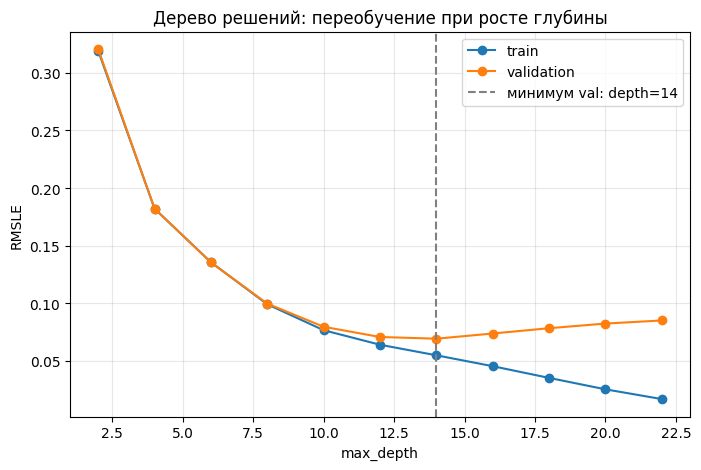

In [16]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error

depths = list(range(2, 23, 2))
train_err, val_err = [], []

for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, random_state=42)
    tree.fit(X_train, y_train)
    train_err.append(root_mean_squared_error(y_train, tree.predict(X_train)))
    val_err.append(root_mean_squared_error(y_val, tree.predict(X_val)))

best_d = depths[int(np.argmin(val_err))]

plt.figure(figsize=(8, 5))
plt.plot(depths, train_err, marker='o', label='train')
plt.plot(depths, val_err, marker='o', label='validation')
plt.axvline(best_d, color='gray', linestyle='--', label=f'минимум val: depth={best_d}')
plt.xlabel('max_depth')
plt.ylabel('RMSLE')
plt.title('Дерево решений: переобучение при росте глубины')
plt.legend()
plt.grid(alpha=0.3)

os.makedirs('images', exist_ok=True)
plt.savefig('images/tree_depth_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [17]:
# Случайный лес
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

model = RandomForestRegressor(n_estimators=30, max_depth=14,
                              n_jobs=-1, random_state=42)
model.fit(X_train, y_train)

err_train = root_mean_squared_error(y_train, model.predict(X_train))
err_val   = root_mean_squared_error(y_val,   model.predict(X_val))
print(err_train, err_val)

0.051078867239946514 0.06265092443288997


In [18]:
# CatBoost
from catboost import CatBoostRegressor

model = CatBoostRegressor(
    iterations=5000,          # максимум деревьев
    learning_rate=0.05,        # вклад каждого дерева
    depth=6,                  # глубина каждого дерева
    loss_function='RMSE',
    random_seed=42,
    verbose=200,              # печатать прогресс
)
model.fit(X_train, y_train,
          eval_set=(X_val, y_val),        # на чём следить за ошибкой
          early_stopping_rounds=100)      # стоп, если 100 деревьев без улучшения

pred = model.predict(X_val)
print(root_mean_squared_error(y_val, pred), model.get_best_iteration())

0:	learn: 0.9182692	test: 0.9195849	best: 0.9195849 (0)	total: 129ms	remaining: 10m 46s
200:	learn: 0.0608856	test: 0.0618286	best: 0.0618286 (200)	total: 10.6s	remaining: 4m 12s
400:	learn: 0.0590819	test: 0.0606202	best: 0.0606202 (400)	total: 20.9s	remaining: 3m 59s
600:	learn: 0.0584079	test: 0.0603499	best: 0.0603499 (600)	total: 31.3s	remaining: 3m 49s
800:	learn: 0.0579599	test: 0.0601996	best: 0.0601967 (791)	total: 41.8s	remaining: 3m 38s
1000:	learn: 0.0576319	test: 0.0601068	best: 0.0601068 (1000)	total: 51.9s	remaining: 3m 27s
1200:	learn: 0.0573614	test: 0.0600631	best: 0.0600591 (1180)	total: 1m 2s	remaining: 3m 16s
1400:	learn: 0.0571397	test: 0.0600173	best: 0.0600157 (1397)	total: 1m 12s	remaining: 3m 6s
1600:	learn: 0.0569382	test: 0.0599715	best: 0.0599715 (1600)	total: 1m 22s	remaining: 2m 55s
1800:	learn: 0.0567572	test: 0.0599558	best: 0.0599550 (1796)	total: 1m 33s	remaining: 2m 45s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.0599471267
b

In [19]:
# Насколько модель опирается на каждый признак
importance_features = pd.Series(model.get_feature_importance(), index=X_train.columns).sort_values(ascending=False)
importance_features

Duration      73.288422
Heart_Rate    15.568817
Age            6.176988
Body_Temp      2.292565
Sex_male       2.215403
Weight         0.408874
Height         0.048932
dtype: float64

In [20]:
X_base = df.drop(columns=['id', 'Calories'])
X_base = pd.get_dummies(X_base, columns=['Sex'], drop_first=True, dtype=int)

X_fe = add_features(X_base)
X_train_fe, X_val_fe, y_train, y_val = train_test_split(X_fe, y, test_size=0.1, random_state=42)
print(X_fe.shape)   # (750000, 10)

(750000, 10)


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_fe)  # fit: считает среднее и std ПО TRAIN, transform: применяет
X_val_sc = scaler.transform(X_val_fe)          # только transform: используем числа, посчитанные на train

In [22]:
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.pipeline import make_pipeline

lin = LinearRegression().fit(X_train_fe, y_train)
print('Linear, 10 признаков:', root_mean_squared_error(y_val, lin.predict(X_val_fe)))

sgd = SGDRegressor(random_state=42).fit(X_train_fe, y_train)
print('SGD без масштабирования:', root_mean_squared_error(y_val, sgd.predict(X_val_fe)))

sgd_sc = make_pipeline(StandardScaler(), SGDRegressor(random_state=42))
sgd_sc.fit(X_train_fe, y_train)
print('SGD с масштабированием:', root_mean_squared_error(y_val, sgd_sc.predict(X_val_fe)))

Linear, 10 признаков: 0.14545779410103582


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:1608: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


SGD без масштабирования: 343102723667341.75
SGD с масштабированием: 0.14627979640435732


In [23]:
# test = pd.read_csv('/kaggle/input/competitions/playground-series-s5e5/test.csv')

# test_ids = test['id']
# X_test = test.drop(columns=['id'])
# X_test = pd.get_dummies(X_test, columns=['Sex'], drop_first=True, dtype=int)

# X_test = add_features(X_test)
# X_test = X_test[X_train.columns]

# pred = np.expm1(model.predict(X_test))
# submission = pd.DataFrame({'id': test_ids, 'Calories': pred})


# print(submission.shape)
# print(submission['Calories'].describe())
# print(submission.isna().sum().sum())
# submission.to_csv('/kaggle/working/submission.csv', index=False)

In [24]:
# 1. Те же признаки, но обучаемся на ВСЕХ данных (без train_test_split)
X_base = df.drop(columns=['id', 'Calories'])
X_base = pd.get_dummies(X_base, columns=['Sex'], drop_first=True, dtype=int)
X_fe = add_features(X_base)
y = np.log1p(df['Calories'])

# 2. Число деревьев: лучшая итерация с валидации × 1.1 (данных стало на 10% больше)
n_trees = int(1900 * 1.1)   # подставь свой model.get_best_iteration() для lr=0.1

# 3. Без eval_set и early_stopping_rounds
final_model = CatBoostRegressor(
    iterations=n_trees, learning_rate=0.1, depth=6,
    loss_function='RMSE', random_seed=42, verbose=200,
    allow_writing_files=False,
)
final_model.fit(X_fe, y)

# 4. Test: тот же конвейер, колонки в том же порядке
test = pd.read_csv('/kaggle/input/competitions/playground-series-s5e5/test.csv')
test_ids = test['id']
X_test = test.drop(columns=['id'])
X_test = pd.get_dummies(X_test, columns=['Sex'], drop_first=True, dtype=int)
X_test = add_features(X_test)
X_test = X_test[X_fe.columns]

pred = np.expm1(final_model.predict(X_test))
submission = pd.DataFrame({'id': test_ids, 'Calories': pred})
submission.to_csv('/kaggle/working/submission.csv', index=False)

0:	learn: 0.8727605	total: 77.7ms	remaining: 2m 42s
200:	learn: 0.0604790	total: 12.6s	remaining: 1m 58s
400:	learn: 0.0589634	total: 25.3s	remaining: 1m 46s
600:	learn: 0.0581585	total: 37.8s	remaining: 1m 33s
800:	learn: 0.0575793	total: 50.2s	remaining: 1m 20s
1000:	learn: 0.0571351	total: 1m 2s	remaining: 1m 8s
1200:	learn: 0.0567812	total: 1m 14s	remaining: 55.5s
1400:	learn: 0.0564624	total: 1m 27s	remaining: 42.9s
1600:	learn: 0.0561657	total: 1m 39s	remaining: 30.5s
1800:	learn: 0.0558916	total: 1m 52s	remaining: 18s
2000:	learn: 0.0556445	total: 2m 4s	remaining: 5.54s
2089:	learn: 0.0555553	total: 2m 10s	remaining: 0us


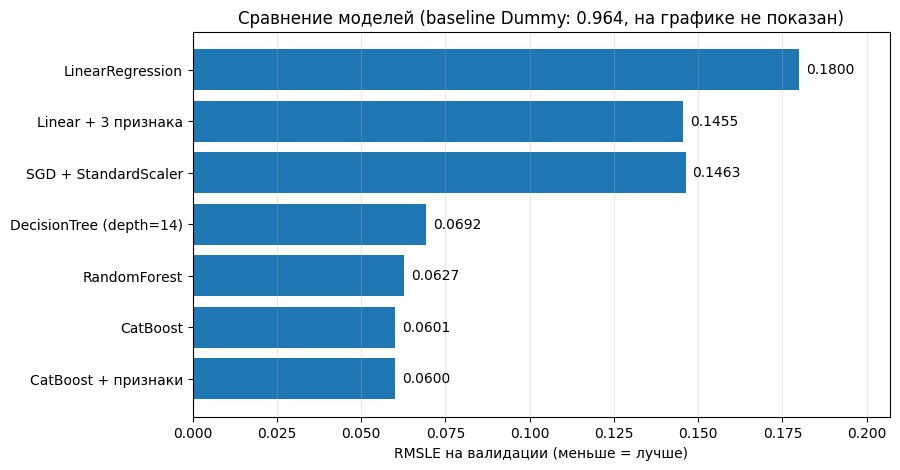

In [25]:
results = {
    'LinearRegression':        0.180,
    'Linear + 3 признака':     0.1455,
    'SGD + StandardScaler':    0.1463,
    'DecisionTree (depth=14)': 0.0692,
    'RandomForest':            0.0627,
    'CatBoost':                0.0601,
    'CatBoost + признаки':     0.0600,
}

names = list(results.keys())[::-1]      # чтобы лучшая модель была сверху
values = list(results.values())[::-1]

plt.figure(figsize=(9, 5))
bars = plt.barh(names, values)
for bar, v in zip(bars, values):
    plt.text(v + 0.002, bar.get_y() + bar.get_height() / 2, f'{v:.4f}', va='center')

plt.xlabel('RMSLE на валидации (меньше = лучше)')
plt.title('Сравнение моделей (baseline Dummy: 0.964, на графике не показан)')
plt.xlim(0, max(values) * 1.15)
plt.grid(axis='x', alpha=0.3)

os.makedirs('images', exist_ok=True)
plt.savefig('images/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

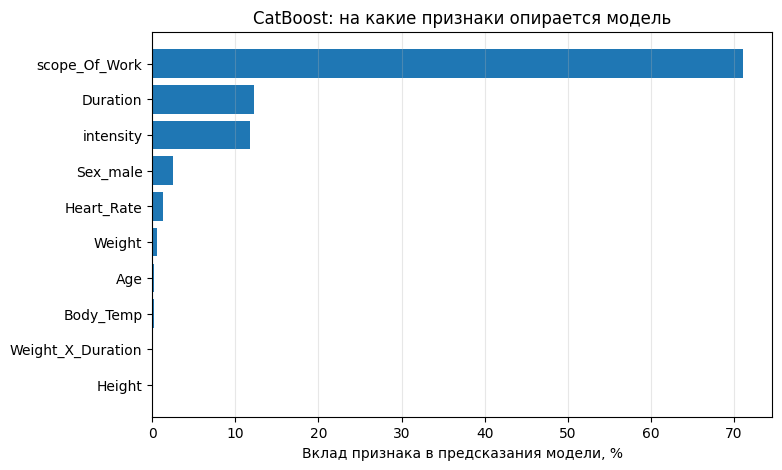

In [26]:
imp = pd.Series(final_model.get_feature_importance(), index = X_fe.columns).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(imp.index, imp.values)
plt.xlabel('Вклад признака в предсказания модели, %')
plt.title('CatBoost: на какие признаки опирается модель')
plt.grid(axis='x', alpha=0.3)

os.makedirs('images', exist_ok=True)
plt.savefig('images/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()